# 26 · Likely buyers of a token (work package 15)

**Work package 15** of the [applications plan](../../research/implementation_plan_applications.md), section 15.
The recommender read by token: for a token, rank the accounts most likely to pick it up in the two days after an
evaluation point. Uses: the audience of an airdrop or a promotion, or whom a wallet shows a token to.

- **Audience:** accounts with at least one token in their 14-day window that never traded the token before.
- **Tokens scored:** universe tokens with at least 10 buyers in the audience in the next two days.
- **Metrics per token:** recall@1000 (share of its buyers among the first 1,000 accounts) and precision@100.
  Each point's value is the mean over its tokens.
- **Baselines:** *activity* (accounts by number of tokens in their 14-day window, the same order for every token)
  and *random*.

**Scores** (`src/scripts/audience.py`):

| Method | Score of account $u$ for token $i$ | Role |
| --- | --- | --- |
| model | the fixed blend's column: $\mathrm{knn}_{ui} / \max_j \mathrm{knn}_{uj}$ | the plan's score, **primary** |
| raw neighbours | $\mathrm{knn}_{ui}$ (sum of similarities from the account's tokens) | variant |
| model × activity | model × window size | variant |
| model × log activity | model × log(1 + window size) | variant |

The variants were added after the plan's score lost to activity at a first look (`project_direction.md`,
24 November). One is chosen on the Dev A points and is a **secondary** result.

**Criterion (stated in the plan):** on the 14 test points, the mean paired difference in recall@1000 between the
score and activity is positive, with a 95% bootstrap interval over points that excludes zero.

In [1]:
import sys

sys.path.append("../scripts")

import matplotlib.pyplot as plt
import pandas as pd

import plots
import protocol as pc
import stats

plots.style()
pd.set_option("display.float_format", "{:,.3f}".format)
WP15 = pc.RESULTS_DIR / "wp15"
PARTS = ["dev_a", "dev_b", "test"]
VARIANTS = ["raw neighbours", "model x activity", "model x log activity"]
tokens = {part: pd.read_parquet(WP15 / f"tokens_{part}.parquet") for part in PARTS}
without_farms = {part: pd.read_parquet(WP15 / f"tokens_{part}_without_farms.parquet") for part in ("dev_b", "test")}


def per_point(table: pd.DataFrame, metric: str = "recall_1000") -> pd.DataFrame:
    """Mean of a metric over the scored tokens of each point, per method: one row per (method, point)."""
    return table.groupby(["method", "point"])[metric].mean().reset_index()


pd.DataFrame({part: {"points": t["point"].nunique(), "tokens scored (mean per point)": t[t["method"] == "model"].groupby("point").size().mean(),
                     "audience (mean)": t.groupby("point")["audience"].first().mean(),
                     "buyers per token (median)": t.loc[t["method"] == "model", "buyers"].median()} for part, t in tokens.items()})  # fmt: skip

,dev_a,dev_b,test
points,10.000,11.000,14.000
tokens scored (mean per point),280.400,247.182,304.357
audience (mean),"162,769.100","121,994.818","142,495.214"
buyers per token (median),17.000,17.000,19.000


## 1. Choosing the variant on Dev A

Mean recall@1000 over the 10 Dev A points for every method. The variant with the highest mean is chosen.

In [2]:
dev_a = per_point(tokens["dev_a"]).groupby("method")["recall_1000"].agg(["mean", "min", "max"]).sort_values("mean", ascending=False)
dev_a

,mean,min,max
method,,,
raw neighbours,0.498,0.476,0.545
model x activity,0.487,0.459,0.541
model x log activity,0.450,0.412,0.488
activity,0.401,0.382,0.425
model,0.066,0.053,0.095
random,0.007,0.004,0.008


In [3]:
CHOSEN = dev_a.loc[VARIANTS, "mean"].idxmax()
print(f"Chosen variant (on Dev A): {CHOSEN!r}")

Chosen variant (on Dev A): 'raw neighbours'


## 2. Dev B and test: against activity

The standard paired comparison (`stats.compare`) with activity as the reference, over the points of each part.
The criterion is read from the test rows: the primary (model) and the chosen variant each need a positive mean
difference whose interval excludes zero.

In [4]:
def compare(table: pd.DataFrame, metric: str = "recall_1000") -> pd.DataFrame:
    """stats.compare of model, the chosen variant and random against activity."""
    points = per_point(table, metric)
    results = {m: points[points["method"] == m][["point", metric]] for m in ["activity", "model", CHOSEN, "random"]}
    return stats.compare(results, baseline="activity", metric=metric)


comparisons = {part: compare(tokens[part]) for part in ("dev_b", "test")}
pd.concat(comparisons, names=["part"]).droplevel(1)

,model,points,mean,lowest,highest,mean_difference,interval_low,interval_high,wins,sign_test_p
part,,,,,,,,,,
dev_b,activity,11,0.369,0.335,0.393,NaN,NaN,NaN,NaN,NaN
dev_b,model,11,0.081,0.068,0.101,-0.288,-0.302,-0.274,0 of 11,0.001
dev_b,raw neighbours,11,0.471,0.447,0.499,0.102,0.091,0.112,11 of 11,0.001
dev_b,random,11,0.008,0.006,0.010,-0.361,-0.371,-0.351,0 of 11,0.001
test,activity,14,0.317,0.253,0.363,NaN,NaN,NaN,NaN,NaN
test,model,14,0.067,0.042,0.101,-0.250,-0.263,-0.236,0 of 14,0.000
test,raw neighbours,14,0.438,0.357,0.503,0.122,0.114,0.128,14 of 14,0.000
test,random,14,0.007,0.005,0.010,-0.310,-0.327,-0.291,0 of 14,0.000


In [5]:
for name in ["model", CHOSEN]:
    row = comparisons["test"].set_index("model").loc[name]
    met = row["mean_difference"] > 0 and row["interval_low"] > 0
    role = "primary" if name == "model" else "secondary (chosen on Dev A)"
    print(f"{name} ({role}): test difference {row['mean_difference']:+.3f} "
          f"[{row['interval_low']:+.3f}, {row['interval_high']:+.3f}], wins {row['wins']} -> criterion {'MET' if met else 'NOT met'}")  # fmt: skip

model (primary): test difference -0.250 [-0.263, -0.236], wins 0 of 14 -> criterion NOT met
raw neighbours (secondary (chosen on Dev A)): test difference +0.122 [+0.114, +0.128], wins 14 of 14 -> criterion MET


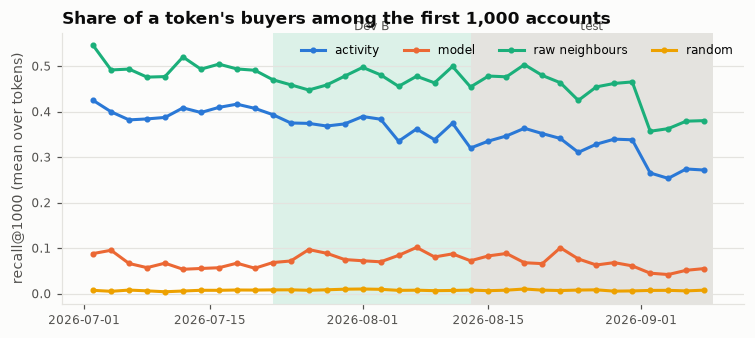

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.2))
points = pd.concat([per_point(tokens[p]) for p in PARTS])
for slot, method in enumerate(["activity", "model", CHOSEN, "random"]):
    series = points[points["method"] == method].sort_values("point")
    ax.plot(series["point"], series["recall_1000"], marker="o", markersize=3, color=plots.SERIES[slot], label=method)
plots.shade_periods(ax, {"Dev B": (pc.DEV_B_START, pc.TEST_START), "test": (pc.TEST_START, points["point"].max() + pd.Timedelta(days=1))})
ax.set_ylabel("recall@1000 (mean over tokens)")
ax.set_title("Share of a token's buyers among the first 1,000 accounts")
ax.legend(ncol=4, fontsize=8)
plt.show()

## 3. Precision@100

Of the first 100 accounts per token, the share that buy it: what a small, targeted audience would get.

In [7]:
pd.concat({part: compare(tokens[part], "precision_100") for part in ("dev_b", "test")}, names=["part"]).droplevel(1)

,model,points,mean,lowest,highest,mean_difference,interval_low,interval_high,wins,sign_test_p
part,,,,,,,,,,
dev_b,activity,11,0.022,0.016,0.029,NaN,NaN,NaN,NaN,NaN
dev_b,model,11,0.004,0.003,0.006,-0.018,-0.021,-0.016,0 of 11,0.001
dev_b,raw neighbours,11,0.039,0.030,0.047,0.017,0.015,0.019,11 of 11,0.001
dev_b,random,11,0.000,0.000,0.000,-0.022,-0.025,-0.020,0 of 11,0.001
test,activity,14,0.018,0.013,0.026,NaN,NaN,NaN,NaN,NaN
test,model,14,0.004,0.002,0.007,-0.014,-0.016,-0.012,0 of 14,0.000
test,raw neighbours,14,0.038,0.032,0.046,0.020,0.019,0.021,14 of 14,0.000
test,random,14,0.000,0.000,0.000,-0.018,-0.020,-0.016,0 of 14,0.000


## 4. Popular head and tail tokens

Mean recall@1000 over test tokens, split by whether the token is in the popular head at the point.

In [8]:
test = tokens["test"]
test[test["method"].isin(["activity", "model", CHOSEN, "random"])].groupby(["in_head", "method"])["recall_1000"].mean().unstack("in_head")

in_head,False,True
method,,
activity,0.350,0.209
model,0.074,0.044
random,0.007,0.007
raw neighbours,0.472,0.323


## 5. Without the farm groups

The same comparison with WP10's farm groups left out of the audience and of the buyers (groups built on Dev A for
Dev B, on Dev A + Dev B for test).

In [9]:
pd.concat({part: compare(without_farms[part]) for part in ("dev_b", "test")}, names=["part"]).droplevel(1)

,model,points,mean,lowest,highest,mean_difference,interval_low,interval_high,wins,sign_test_p
part,,,,,,,,,,
dev_b,activity,11,0.335,0.304,0.352,NaN,NaN,NaN,NaN,NaN
dev_b,model,11,0.073,0.061,0.091,-0.262,-0.273,-0.250,0 of 11,0.001
dev_b,raw neighbours,11,0.428,0.403,0.454,0.094,0.082,0.105,11 of 11,0.001
dev_b,random,11,0.008,0.005,0.011,-0.327,-0.335,-0.318,0 of 11,0.001
test,activity,14,0.294,0.222,0.360,NaN,NaN,NaN,NaN,NaN
test,model,14,0.052,0.034,0.072,-0.242,-0.263,-0.222,0 of 14,0.000
test,raw neighbours,14,0.386,0.299,0.447,0.093,0.086,0.100,14 of 14,0.000
test,random,14,0.007,0.004,0.009,-0.287,-0.308,-0.265,0 of 14,0.000


## 6. How many buyers can the recommender reach?

The share of a token's buyers with any co-trading path from their own tokens (a nonzero neighbour score). The
others can only be reached by activity.

In [10]:
model_rows = pd.concat([t[t["method"] == "model"].assign(part=p) for p, t in tokens.items()])
model_rows.groupby(["part", "in_head"])["buyers_with_path"].mean().unstack("in_head")

in_head,False,True
part,,
dev_a,0.894,0.945
dev_b,0.787,0.972
test,0.823,0.957


## 7. What this shows

- **The plan's score fails its criterion.** Read down the blend's column, the recommender puts only 7% of a token's
  buyers in its first 1,000 accounts on test, against 32% for activity (difference -0.25, 0 of 14 points). The
  blend scales each account's scores to a maximum of 1: that ranks tokens *within* an account, but makes a barely
  active account's best token look as likely as a heavy trader's, while buyers are mostly heavy traders.
- **The model's own neighbour score, unscaled, meets the criterion (secondary result).** Chosen on Dev A, the raw
  neighbour score puts 44% of a token's buyers in the first 1,000 accounts on test, against 32% for activity:
  +0.122 (interval +0.114 to +0.128), better at all 14 test points and all 11 Dev B points. The first 1,000
  accounts are 0.7% of an audience of about 142,000, so this is roughly 60 times better than random.
- **A small audience is twice as precise.** Of the first 100 accounts per token, 3.8% buy it on test, against 1.8%
  for activity.
- **It works for tail tokens too.** Recall@1000 is 0.47 for tokens outside the popular head (activity 0.35) and 0.32
  for head tokens (activity 0.21). Unlike the top-10 lists, this direction of the model is not limited to the head.
- **Not driven by farms.** With WP10's farm groups removed from audience and buyers, the gain is +0.093 on test
  (interval +0.086 to +0.100), 14 of 14 points.
- **Reach:** 79-89% of tail-token buyers and 95-97% of head-token buyers have a co-trading path from their own
  tokens, so most buyers are reachable by the model at all.
- **What it means:** the recommender's co-trading similarities are a strong audience-targeting tool: "accounts whose
  tokens are similar to this one" beats "the most active accounts" by a wide, stable margin. The lesson for the
  blend is that the per-account scaling, harmless for top-10 lists, has to be undone when accounts are compared with
  each other.